# 02. Logistic Regression

**Project** · Student Placement Prediction  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

Logistic regression estimates the probability of a class by putting an additive model on log-odds. A threshold turns that probability into a label. A campus placement example shows why two students can receive different risk scores even when both cross the same threshold.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

CGPA, aptitude, coding practice and communication add to a weighted log-odds score. Completing an internship adds 0.75 to that score. A sigmoid converts the score to a probability, then a Bernoulli draw produces Placed or Not Placed. Similar profiles can have different outcomes.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `cgpa` | decimal | points out of 10 | Cumulative grade-point average |
| `aptitude_score` | integer | points out of 100 | Aptitude assessment score |
| `coding_problems_solved` | integer | count | Practice problems completed |
| `internship_experience` | string | Yes or No | Whether an internship was completed |
| `communication_score` | integer | points out of 100 | Communication assessment score |
| `placement` | string | Not Placed, Placed | Observed class label |

**Independent variables (X)** · `cgpa`, `aptitude_score`, `coding_problems_solved`, `internship_experience`, `communication_score`.

**Dependent variable (y)** · `placement` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "02_student_placement.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,cgpa,aptitude_score,coding_problems_solved,internship_experience,communication_score,placement
0,7.60,61,180,Yes,85.0,Not Placed
1,5.71,99,60,Yes,39.0,Not Placed
2,8.18,63,15,Yes,43.0,Not Placed
3,5.98,46,72,No,59.0,Not Placed
4,9.89,43,145,Yes,84.0,Placed
5,7.60,50,130,Yes,87.0,Placed
6,9.26,95,143,No,42.0,Not Placed
7,5.87,81,79,No,95.0,Not Placed
8,8.31,79,188,No,58.0,Not Placed
9,6.30,93,10,Yes,79.0,Not Placed


cgpa                      float64
aptitude_score              int64
coding_problems_solved      int64
internship_experience         str
communication_score       float64
placement                     str
dtype: object

## 3. Mathematical Understanding

Compute $z=b+\sum_{j=1}^p w_j x_j$ and $q=P(y=1\mid x)=1/(1+e^{-z})$. Here $x_j$ is transformed feature $j$, $p$ is the feature count, $w_j$ its coefficient, $b$ the intercept, $e$ Euler’s number, and $q$ the positive-class probability. Binary log loss for one example is $-[y\ln q+(1-y)\ln(1-q)]$, with known label $y\in\{0,1\}$. Fitting minimizes the training loss plus a regularization penalty.

A score of $z=1.1$ gives $q\approx0.75$. With threshold $0.50$ the class is Placed. With threshold $0.80$ the same probability yields Not Placed. A one-unit increase in a feature multiplies the odds by $e^{w_j}$ at fixed values of the other features.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression)

## 4. Working Principle

Build a scorecard from aptitude, practice and the other factors. The sigmoid compresses the score to a probability. A threshold turns the probability into a class. Test alternative thresholds on validation data when the decision costs change.

| Step | Result |
| --- | --- |
| Linear score | 1.10 |
| Positive probability | 0.7503 |
| Threshold 0.50 | Placed |
| Threshold 0.80 | Not Placed |

**Workflow diagram**

`Raw input` → `Standardized numeric values and any category indicators` → `Applies a sigmoid to an additive log-odds model` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. Pearson correlation measures linear association. The category target is excluded. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "placement"
FEATURES = ["cgpa","aptitude_score","coding_problems_solved","internship_experience","communication_score"]
NUMERIC = ["cgpa","aptitude_score","coding_problems_solved","communication_score"]
CATEGORICAL = ["internship_experience"]
SEED = 42
LABELS = ["Not Placed","Placed"]

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cgpa                    1500 non-null   float64
 1   aptitude_score          1500 non-null   int64  
 2   coding_problems_solved  1500 non-null   int64  
 3   internship_experience   1470 non-null   str    
 4   communication_score     1470 non-null   float64
 5   placement               1500 non-null   str    
dtypes: float64(2), int64(2), str(2)
memory usage: 86.0 KB


,cgpa,aptitude_score,coding_problems_solved,internship_experience,communication_score,placement
0,7.60,61,180,Yes,85.0,Not Placed
1,5.71,99,60,Yes,39.0,Not Placed
2,8.18,63,15,Yes,43.0,Not Placed
3,5.98,46,72,No,59.0,Not Placed
4,9.89,43,145,Yes,84.0,Placed


,cgpa,aptitude_score,coding_problems_solved,internship_experience,communication_score,placement
1495,9.45,56,119,No,78.0,Placed
1496,7.52,56,156,Yes,69.0,Placed
1497,9.41,60,172,No,74.0,Placed
1498,5.82,47,37,No,56.0,Not Placed
1499,6.32,88,181,No,93.0,Not Placed


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cgpa,1500.0,NaN,NaN,NaN,7.775067,1.309982,5.51,6.64,7.78,8.92,10.0
aptitude_score,1500.0,NaN,NaN,NaN,67.860667,19.220151,35.0,51.0,68.0,85.0,100.0
coding_problems_solved,1500.0,NaN,NaN,NaN,102.341333,57.109104,0.0,52.75,104.0,152.0,200.0
internship_experience,1470,2,No,790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
communication_score,1470.0,NaN,NaN,NaN,67.406803,18.701968,35.0,51.0,68.0,84.0,100.0
placement,1500,2,Not Placed,788,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Missing %
cgpa,0,0.0
aptitude_score,0,0.0
coding_problems_solved,0,0.0
internship_experience,30,2.0
communication_score,30,2.0
placement,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

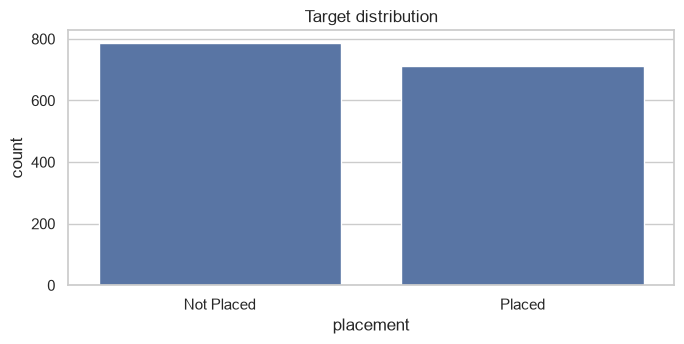

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

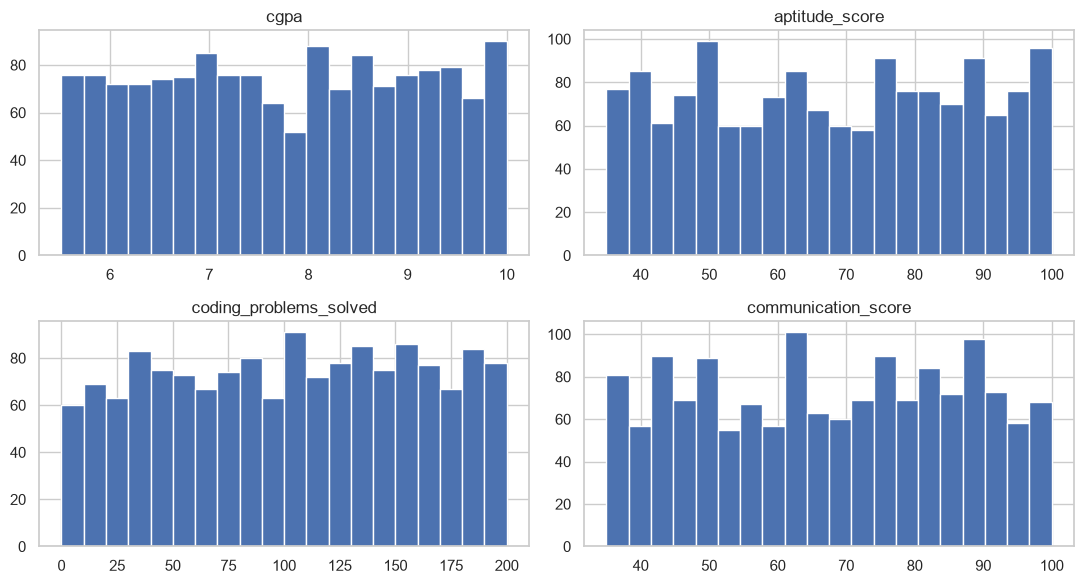

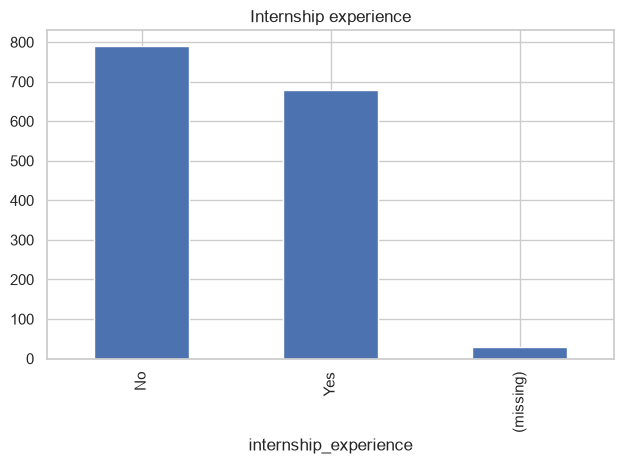

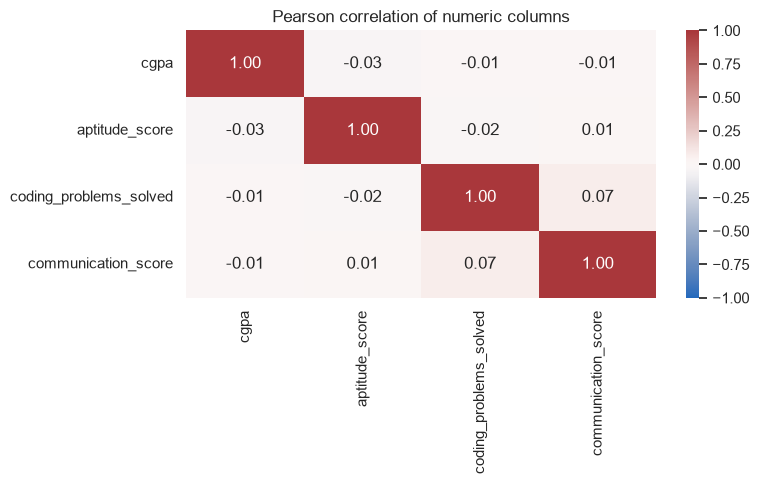

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

df["internship_experience"].fillna("(missing)").value_counts().plot.bar()
plt.title("Internship experience")
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. Stratification preserves approximate class proportions. The numeric branch fills blanks using training medians. The categorical branch fills blanks with the most common training level and one-hot encodes levels. An unseen level becomes an all-zero block. StandardScaler uses training means and standard deviations to make numeric magnitudes comparable. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
label_codes = {'Not Placed': 0, 'Placed': 1}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

# Fill blank numbers, then put numeric columns on comparable scales.
numeric_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

# Fill blank categories, then make one indicator column per category.
category_preprocess = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
        ("categorical", category_preprocess, CATEGORICAL),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`C` is inverse regularization strength with the default L2 configuration. Smaller `C` shrinks coefficients more. `max_iter` caps optimization iterations. Scaling helps the optimizer and makes coefficient shrinkage comparable across numeric columns.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.linear_model import LogisticRegression

estimator = LogisticRegression(C=1.0, max_iter=1000)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['cgpa','aptitude_score','coding_problems_solved','internship_experience', 'communication_score']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that featu

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

,cgpa,aptitude_score,coding_problems_solved,internship_experience,communication_score
875,5.91,99,89,No,35.0


Example predicted class: Not Placed


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

The positive class is **Placed**. ROC-AUC ranks by its estimated probability. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

AVERAGE = "binary"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.predict_proba(X_test)[:, 1]

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.707
Precision    0.721
Recall       0.620
F1           0.667
ROC-AUC      0.797
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.527,0.000,0.00,0.000,0.500
Model,0.707,0.721,0.62,0.667,0.797


### Read the results for each class

In [14]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

  Not Placed       0.70      0.78      0.74       158
      Placed       0.72      0.62      0.67       142

    accuracy                           0.71       300
   macro avg       0.71      0.70      0.70       300
weighted avg       0.71      0.71      0.70       300



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. The ROC curve shows the recall and false-positive trade-off across score thresholds.

The ROC curve describes ranking over many thresholds. The threshold plot instead shows how one example’s label changes as its threshold crosses its predicted placement probability.

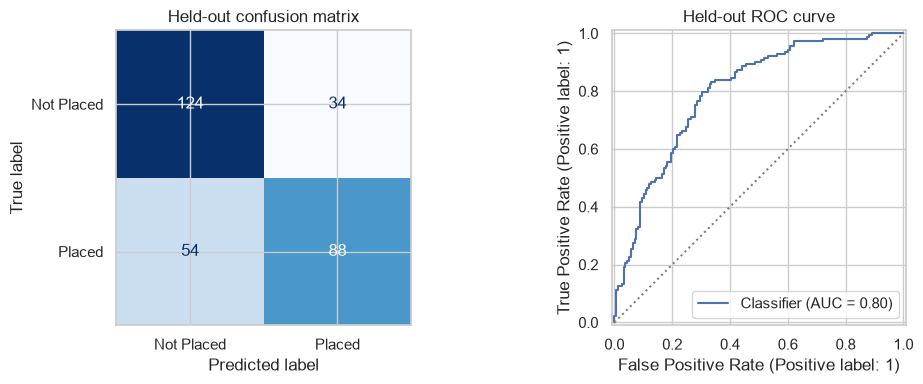

In [15]:
fig, (ax, roc_ax) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_scores, pos_label=1, ax=roc_ax)
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
roc_ax.set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()

### A closer look at this model

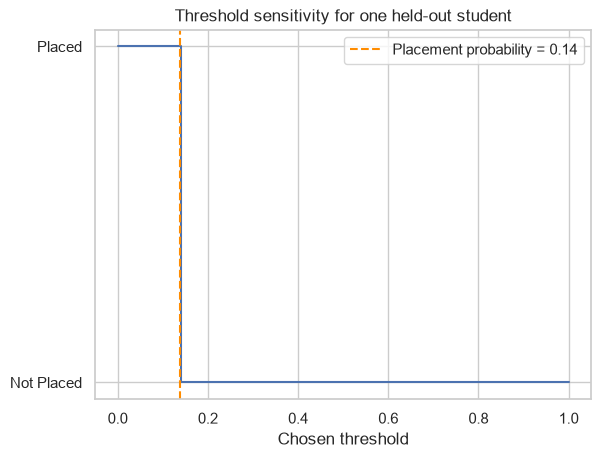

In [16]:
p_placed = model.predict_proba(X_test.iloc[[0]])[0, 1]
cutoffs = np.linspace(0, 1, 101)
fig, ax = plt.subplots()
ax.step(cutoffs, (p_placed >= cutoffs).astype(int), where="post")
ax.axvline(p_placed, color="darkorange", linestyle="--", label=f"Placement probability = {p_placed:.2f}")
ax.set(xlabel="Chosen threshold", yticks=[0, 1], yticklabels=LABELS, title="Threshold sensitivity for one held-out student")
ax.legend()
plt.show()

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled stratified folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by positive-class F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`C` is inverse regularization strength with the default L2 configuration. Smaller `C` shrinks coefficients more. `max_iter` caps optimization iterations. Scaling helps the optimizer and makes coefficient shrinkage comparable across numeric columns.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"model__C": [0.03, 0.3, 1, 10]}
validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [18]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__C': 0.3}


,rank_test_score,Mean CV F1,std_test_score,params
1,1,0.718,0.019,{'model__C': 0.3}
3,1,0.718,0.019,{'model__C': 10}
2,3,0.717,0.020,{'model__C': 1}
0,4,0.714,0.020,{'model__C': 0.03}


### Compare the models on the test set

In [19]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.527,0.000,0.000,0.000,0.500
First model,0.707,0.721,0.620,0.667,0.797
Tuned model,0.703,0.719,0.613,0.662,0.797


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population.

### Enter three new examples

In [20]:
examples = pd.DataFrame([
    [7.1, 64, 45, 'No', 68],
    [8.8, 82, 140, 'Yes', 84],
    [7.9, 76, 95, 'No', 78],
], columns=FEATURES)
display(examples)

,cgpa,aptitude_score,coding_problems_solved,internship_experience,communication_score
0,7.1,64,45,No,68
1,8.8,82,140,Yes,84
2,7.9,76,95,No,78


### Make predictions

In [21]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Limited practice and no internship","High scores and internship experience","Mid-range profile with no internship"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,cgpa,aptitude_score,coding_problems_solved,internship_experience,communication_score,Scenario,Predicted class,P(Not Placed),P(Placed)
0,7.1,64,45,No,68,Limited practice and no internship,Not Placed,0.855,0.145
1,8.8,82,140,Yes,84,High scores and internship experience,Placed,0.082,0.918
2,7.9,76,95,No,78,Mid-range profile with no internship,Placed,0.488,0.512


## 12. Limitations and Advantages

It is efficient and gives coefficients and probability estimates. Additivity in log-odds is an assumption, so strong interactions may be missed. Low `C` can underfit and high `C` can make estimates unstable, especially with separation. Check calibration before treating probabilities as frequencies. Use it for an interpretable classification baseline. Use engineered features or another model if an additive boundary repeatedly misses patterns.

## 13. Interview Preparation

### A. 30-second explanation

> I fitted logistic regression to predict placement from academic, practice and communication features. Its sigmoid converts a weighted score into a probability. I kept preprocessing inside the pipeline, tuned regularization on training folds and used precision, recall and ROC-AUC to explain the held-out results.

### B. 90-second technical explanation

> I fitted logistic regression to predict placement from academic, practice and communication features. Its sigmoid converts a weighted score into a probability. I kept preprocessing inside the pipeline, tuned regularization on training folds and used precision, recall and ROC-AUC to explain the held-out results. My target was placement, and the inputs were cgpa, aptitude score, coding problems solved, internship experience, communication score. Build a scorecard from aptitude, practice and the other factors. The sigmoid compresses the score to a probability. A threshold turns the probability into a class. Test alternative thresholds on validation data when the decision costs change. I held out 20% of the rows and fitted preprocessing within each training fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **Why is this a classifier?** It models a class probability and maps it to a class.
2. **What are log-odds?** The logarithm of p divided by 1 minus p.
3. **Why use the sigmoid?** It maps any real-valued score to a probability between zero and one.
4. **What happens when C decreases?** The coefficients are shrunk more strongly.
5. **Does changing a threshold change ROC-AUC?** No. ROC-AUC aggregates the ranking across thresholds.
6. **What is calibration?** Among rows scored near a probability, the observed outcome rate should be close to that probability.
7. **Why use a stratified split?** It preserves class proportions approximately in training and test.
8. **What does a negative coefficient mean?** Higher transformed feature values correspond to lower positive-class log-odds with the other values held fixed.
9. **What is complete separation?** A boundary classifies the training set perfectly and unpenalized coefficients can diverge.
10. **Why use log loss for fitting?** Confident wrong probabilities receive a large penalty and the objective is appropriate for Bernoulli labels.

### D. Five scenario questions

1. **False negatives are costly. How would you act?** Evaluate a lower threshold against a precision constraint using validation data.
2. **Internship helps at low CGPA only. What would you add?** An internship-CGPA interaction with fold-based validation.
3. **Placement prevalence falls next year. What would you check?** Review calibration and threshold performance on representative recent data.
4. **Training has very few Not Placed examples. Which scores matter?** Inspect class-specific recall, F1 and a precision-recall curve in addition to accuracy.
5. **A score was recorded after graduation. Would you use it?** Exclude it if the prediction must be made before graduation.

### E. Three common mistakes

- Reading a coefficient as a fixed change in probability. Interpret its log-odds change.
- Selecting the threshold on test examples. Use training validation data.
- Encoding internship as arbitrary graded levels. Use a categorical encoder.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [22]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for student placement prediction using Logistic Regression. I generated 1,500 synthetic observations and used cgpa, aptitude score, coding problems solved, internship experience, communication score to predict placement. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} F1 for Placed, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I inspected how one placement decision changed as the probability threshold moved. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for student placement prediction using Logistic Regression. I generated 1,500 synthetic observations and used cgpa, aptitude score, coding problems solved, internship experience, communication score to predict placement. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.662 F1 for Placed, versus 0.000 for the baseline, with ROC-AUC 0.797. I inspected how one placement decision changed as the probability threshold moved. These results apply to the synthetic data and should be validated on representative observations before practical use.